# Simulation 19: Heuristics vs. Baselines

TJ Kim
3/24/22

Run the second simulation with the following considerations.

- 10 Servers, 20 TS, 15 Users --> increase servers to 20 and users to 40
- Use ONE-mobility --> crawdad
- Job lengths: vr = 10-15, Assist = 5-10, AR = 10-15
- We share the same users and jobs between simulations

Resources: Normal
- All jobs are run with standard Quantity
- 14 level 1, 5 level 2, 1 level 3

In [1]:
from IPython.core.debugger import set_trace

# Import Generic Classes
import numpy as np
import copy
import pickle
import random

# Import All Custom Classes
import os, sys
sys.path.append(os.path.pardir+"/classes")
sys.path.append(os.path.pardir+"/solvers")
sys.path.append(os.path.pardir+"/one_mobility")
sys.path.append(os.path.curdir + "/sim_store/sim19")


from Server import *
from User import *
from Link import *
from Job import *
from Migration_Plans import *
from Cost_Recordings import *

from sim19_setting import *
# from sim19_setting_half import *
# from sim19_setting_double import *

# Import Solver Classes
from Optim_PlanGenerator import *
from SeqGreedy_PlanGenerator import *
from Myopic_PlanGenerator import *
from Naive_PlanGenerator import *
from Cloud_PlanGenerator import *

### Run Simulation across 10 trials for the groups

Heuristics - Sequential Greedy and Batched

In [7]:
num_trials = 10
Batch_cost_stores = []
SG_cost_stores = []
Naive_cost_stores = []
Myopic_cost_stores = []
Cloud_cost_stores = []

Batch_cost_stores_ample = []
SG_cost_stores_ample = []
Naive_cost_stores_ample = []
Myopic_cost_stores_ample = []
Cloud_cost_stores_ample = []

for i in range(num_trials):
    
    print("Trial Number:",i)
    
    print("limited")
        
    while True:
        try:
            # Make Users
            users, servers, links, jobs, sim_param = simulation_setting()
            # Make Batch Prob 
            print("batch_prob...")
            Batch_prob = SeqGreedy_PlanGenerator(users, servers, links, jobs, sim_param)
            Batch_plan = Migration_Plans(users,jobs,sim_param)
            Batch_plan.from_seq_greedy(Batch_prob)
            Batch_cost_stores += [Cost_Recordings(Batch_plan)]
            print("done!")
            break
        except:
            print("batch_broken, repeating with new users")
            continue
        
    
    # Make SG Prob
    # Set Refresh to false for SG
    refresh_rate = [0,0]
    refresh = False

    jobs2 = copy.deepcopy(jobs)
    for j in range(len(jobs2)):
        jobs2[j].info_from_usr(users[j],refresh_rate,refresh)
    
    print("SG prob...")
    SG_prob = SeqGreedy_PlanGenerator(users, servers, links, jobs2, sim_param)
    SG_plan = Migration_Plans(users,jobs2,sim_param)
    SG_plan.from_seq_greedy(SG_prob)
    SG_cost_stores += [Cost_Recordings(SG_plan)]
    print("done!")
    
    # Make Cloud Prob
    print("Cloud prob...")
    Cloud_prob = Cloud_PlanGenerator(users, servers, links, jobs, sim_param)
    Cloud_plan = Migration_Plans(users,jobs,sim_param)
    Cloud_plan.from_seq_greedy(Cloud_prob)
    Cloud_cost_stores += [Cost_Recordings(Cloud_plan)]
    print("done!")
    
    # Make Naive Prob
    print("Naive prob...")
    Naive_prob = Naive_PlanGenerator(users, servers, links, jobs, sim_param)
    Naive_plan = Migration_Plans(users,jobs,sim_param)
    Naive_plan.from_seq_greedy(Naive_prob)
    Naive_cost_stores += [Cost_Recordings(Naive_plan)]
    print("done!")
    
    # Make Myopic Prob
    print("Myopic prob...")
    Myopic_prob = Myopic_PlanGenerator(users, servers, links, jobs, sim_param)
    Myopic_plan = Migration_Plans(users,jobs,sim_param)
    Myopic_plan.from_seq_greedy(Myopic_prob)
    Myopic_cost_stores += [Cost_Recordings(Myopic_plan)]
    print("done!")
    
#     print("ample")
#     # Make Servers Ample and Run again
#     for s in servers:
#         s.avail_rsrc = np.ones(s.avail_rsrc.shape) * 1000
        
#     # Make Batch Prob
#     print("batch_prob...")
#     Batch_prob = SeqGreedy_PlanGenerator(users, servers, links, jobs, sim_param)
#     Batch_plan = Migration_Plans(users,jobs,sim_param)
#     Batch_plan.from_seq_greedy(Batch_prob)
#     Batch_cost_stores_ample += [Cost_Recordings(Batch_plan)]
#     print("done!")
    
#     # Make SG Prob
#     print("SG prob...")
#     SG_prob = SeqGreedy_PlanGenerator(users, servers, links, jobs2, sim_param)
#     SG_plan = Migration_Plans(users,jobs2,sim_param)
#     SG_plan.from_seq_greedy(SG_prob)
#     SG_cost_stores_ample += [Cost_Recordings(SG_plan)]
#     print("done!")
    
#     # Make Cloud Prob
#     print("Cloud prob...")
#     Cloud_prob = Cloud_PlanGenerator(users, servers, links, jobs, sim_param)
#     Cloud_plan = Migration_Plans(users,jobs,sim_param)
#     Cloud_plan.from_seq_greedy(Cloud_prob)
#     Cloud_cost_stores_ample += [Cost_Recordings(Cloud_plan)]
#     print("done!")
    
#     # Make Naive Prob
#     print("Naive prob...")
#     Naive_prob = Naive_PlanGenerator(users, servers, links, jobs, sim_param)
#     Naive_plan = Migration_Plans(users,jobs,sim_param)
#     Naive_plan.from_seq_greedy(Naive_prob)
#     Naive_cost_stores_ample += [Cost_Recordings(Naive_plan)]
#     print("done!")
    
#     # Make Myopic Prob
#     print("Myopic prob...")
#     Myopic_prob = Myopic_PlanGenerator(users, servers, links, jobs, sim_param)
#     Myopic_plan = Migration_Plans(users,jobs,sim_param)
#     Myopic_plan.from_seq_greedy(Myopic_prob)
#     Myopic_cost_stores_ample += [Cost_Recordings(Myopic_plan)]
#     print("done!")

Trial Number: 0
limited
batch_prob...
Struck Placement Resource (j,s,t): 0 5 2
Struck Placement Resource (j,s,t): 0 5 3
Struck Placement Resource (j,s,t): 7 5 5
Struck Placement Resource (j,s,t): 7 5 6
Struck Placement Resource (j,s,t): 7 5 8
Struck Placement Resource (j,s,t): 7 5 9
Struck Placement Resource (j,s,t): 7 5 4
Struck Placement Resource (j,s,t): 7 5 10
Struck Placement Resource (j,s,t): 10 5 2
Struck Placement Resource (j,s,t): 10 5 3
Struck Placement Resource (j,s,t): 10 5 4
Struck Placement Resource (j,s,t): 10 5 5
Struck Placement Resource (j,s,t): 15 5 2
Struck Placement Resource (j,s,t): 15 5 3
Struck Placement Resource (j,s,t): 15 5 4
Struck Placement Resource (j,s,t): 18 5 2
Struck Placement Resource (j,s,t): 18 5 3
Struck Placement Resource (j,s,t): 18 5 4
Struck Placement Resource (j,s,t): 3 5 5
Struck Placement Resource (j,s,t): 11 5 3
Struck Placement Resource (j,s,t): 11 5 4
Struck Placement Resource (j,s,t): 11 5 5
Struck Placement Resource (j,s,t): 11 5 6
Stru

Struck Placement Resource (j,s,t): 15 5 2
Struck Placement Resource (j,s,t): 15 5 3
Struck Placement Resource (j,s,t): 15 5 4
Struck Placement Resource (j,s,t): 15 5 5
Struck Placement Resource (j,s,t): 15 5 6
Struck Placement Resource (j,s,t): 15 5 8
ban_node: 4
ban_node: 15
ban_node: 26
ban_node: 37
ban_node: 48
ban_node: 70
ban_node: 5
ban_node: 16
ban_node: 27
ban_node: 38
ban_node: 49
ban_node: 71
ban_node: 6
ban_node: 17
ban_node: 28
ban_node: 39
ban_node: 50
ban_node: 72
ban_node: 7
ban_node: 18
ban_node: 29
ban_node: 40
ban_node: 51
ban_node: 73
ban_node: 8
ban_node: 19
ban_node: 30
ban_node: 41
ban_node: 52
ban_node: 74
ban_node: 9
ban_node: 20
ban_node: 31
ban_node: 42
ban_node: 53
ban_node: 75
ban_node: 10
ban_node: 21
ban_node: 32
ban_node: 43
ban_node: 54
ban_node: 76
ban_node: 11
ban_node: 22
ban_node: 33
ban_node: 44
ban_node: 55
ban_node: 77
ban_node: 12
ban_node: 23
ban_node: 34
ban_node: 45
ban_node: 56
ban_node: 78
Struck Placement Resource (j,s,t): 15 5 7
ban_node: 

Struck Placement Resource (j,s,t): 10 5 2
Struck Placement Resource (j,s,t): 10 5 3
Struck Placement Resource (j,s,t): 15 5 2
Struck Placement Resource (j,s,t): 15 5 3
Struck Placement Resource (j,s,t): 18 5 2
Struck Placement Resource (j,s,t): 18 5 3
Struck Placement Resource (j,s,t): 0 5 4
Struck Placement Resource (j,s,t): 10 5 4
Struck Placement Resource (j,s,t): 11 5 3
Struck Placement Resource (j,s,t): 11 5 4
Struck Placement Resource (j,s,t): 15 5 4
Struck Placement Resource (j,s,t): 16 5 3
Struck Placement Resource (j,s,t): 16 5 4
Struck Placement Resource (j,s,t): 18 5 4
Struck Placement Resource (j,s,t): 0 5 5
Struck Placement Resource (j,s,t): 10 5 5
Struck Placement Resource (j,s,t): 11 5 5
Struck Placement Resource (j,s,t): 15 5 5
Struck Placement Resource (j,s,t): 16 5 5
Struck Placement Resource (j,s,t): 18 5 5
Struck Placement Resource (j,s,t): 19 5 4
Struck Placement Resource (j,s,t): 19 5 5
Struck Placement Resource (j,s,t): 0 5 6
Struck Placement Resource (j,s,t): 10

Struck Placement Resource (j,s,t): 19 3 3
Struck Placement Resource (j,s,t): 19 3 4
Struck Placement Resource (j,s,t): 19 3 5
Struck Placement Resource (j,s,t): 3 3 4
Struck Placement Resource (j,s,t): 3 5 4
Struck Placement Resource (j,s,t): 3 3 5
Struck Placement Resource (j,s,t): 7 3 5
Struck Placement Resource (j,s,t): 7 3 6
Struck Placement Resource (j,s,t): 10 3 4
Struck Placement Resource (j,s,t): 10 3 5
Struck Placement Resource (j,s,t): 10 3 6
Struck Placement Resource (j,s,t): 14 3 5
Struck Placement Resource (j,s,t): 14 3 6
Struck Placement Resource (j,s,t): 15 3 5
Struck Placement Resource (j,s,t): 15 3 6
Struck Placement Resource (j,s,t): 15 5 5
Struck Placement Resource (j,s,t): 9 3 6
Struck Placement Resource (j,s,t): 9 3 7
Struck Placement Resource (j,s,t): 19 3 6
Struck Placement Resource (j,s,t): 19 3 7
Struck Placement Resource (j,s,t): 1 3 7
Struck Placement Resource (j,s,t): 10 3 7
Struck Placement Resource (j,s,t): 10 3 8
Struck Placement Resource (j,s,t): 15 3 7


Struck Placement Resource (j,s,t): 15 6 3
Struck Placement Resource (j,s,t): 15 6 4
Struck Placement Resource (j,s,t): 15 6 5
Struck Placement Resource (j,s,t): 15 6 6
Struck Placement Resource (j,s,t): 15 6 7
Struck Placement Resource (j,s,t): 15 6 8
Struck Placement Resource (j,s,t): 15 6 9
ban_node: 5
ban_node: 16
ban_node: 27
ban_node: 38
ban_node: 49
ban_node: 60
ban_node: 71
ban_node: 6
ban_node: 17
ban_node: 28
ban_node: 39
ban_node: 50
ban_node: 61
ban_node: 72
ban_node: 7
ban_node: 18
ban_node: 29
ban_node: 40
ban_node: 51
ban_node: 62
ban_node: 73
ban_node: 8
ban_node: 19
ban_node: 30
ban_node: 41
ban_node: 52
ban_node: 63
ban_node: 74
ban_node: 9
ban_node: 20
ban_node: 31
ban_node: 42
ban_node: 53
ban_node: 64
ban_node: 75
ban_node: 10
ban_node: 21
ban_node: 32
ban_node: 43
ban_node: 54
ban_node: 65
ban_node: 76
ban_node: 11
ban_node: 22
ban_node: 33
ban_node: 44
ban_node: 55
ban_node: 66
ban_node: 77
ban_node: 12
ban_node: 23
ban_node: 34
ban_node: 45
ban_node: 56
ban_node:

batch_prob...
Struck Placement Resource (j,s,t): 13 6 4
Struck Placement Resource (j,s,t): 13 6 5
Struck Placement Resource (j,s,t): 18 6 5
Struck Placement Resource (j,s,t): 19 6 4
Struck Placement Resource (j,s,t): 19 6 5
Struck Placement Resource (j,s,t): 19 4 5
Struck Placement Resource (j,s,t): 18 6 7
done!
SG prob...
done!
Cloud prob...
done!
Naive prob...
Struck Placement Resource (j,s,t): 19 6 4
Struck Placement Resource (j,s,t): 19 6 5
Struck Placement Resource (j,s,t): 19 6 6
Struck Placement Resource (j,s,t): 19 6 7
Struck Placement Resource (j,s,t): 19 4 4
Struck Placement Resource (j,s,t): 19 4 5
Struck Placement Resource (j,s,t): 19 4 6
Struck Placement Resource (j,s,t): 19 4 7
Struck Placement Resource (j,s,t): 19 4 8
done!
Myopic prob...
Struck Placement Resource (j,s,t): 18 4 2
Struck Placement Resource (j,s,t): 5 1 5
Struck Placement Resource (j,s,t): 13 6 4
Struck Placement Resource (j,s,t): 13 6 5
Struck Placement Resource (j,s,t): 19 6 4
Struck Placement Resource (

... (2 outputs left out)

done!
Cloud prob...
Struck Placement Resource (j,s,t): 7 7 3
Struck Placement Resource (j,s,t): 7 7 4
ban_node: 5
ban_node: 16
ban_node: 6
ban_node: 17
ban_node: 7
ban_node: 18
ban_node: 8
ban_node: 19
ban_node: 9
ban_node: 20
ban_node: 10
ban_node: 21
ban_node: 11
ban_node: 22
ban_node: 12
ban_node: 23
ban_node: 13
ban_node: 24
Struck Placement Resource (j,s,t): 16 7 4
ban_node: 16
ban_node: 17
ban_node: 18
ban_node: 19
ban_node: 20
ban_node: 21
ban_node: 22
ban_node: 23
ban_node: 24
Struck Placement Resource (j,s,t): 16 7 5
ban_node: 27
ban_node: 28
ban_node: 29
ban_node: 30
ban_node: 31
ban_node: 32
ban_node: 33
ban_node: 34
ban_node: 35
Struck Placement Resource (j,s,t): 19 7 4
Struck Placement Resource (j,s,t): 19 7 5
Struck Placement Resource (j,s,t): 19 7 6
Struck Placement Resource (j,s,t): 19 7 7
ban_node: 6
ban_node: 17
ban_node: 28
ban_node: 39
ban_node: 7
ban_node: 18
ban_node: 29
ban_node: 40
ban_node: 8
ban_node: 19
ban_node: 30
ban_node: 41
ban_node: 9
ban_node: 20
ban_n

Struck Placement Resource (j,s,t): 7 3 5
Struck Placement Resource (j,s,t): 7 3 4
not enough resources, simulation broken
batch_broken, repeating with new users
batch_prob...
done!
SG prob...
Struck Placement Resource (j,s,t): 0 6 6
Struck Placement Resource (j,s,t): 0 6 7
Struck Placement Resource (j,s,t): 0 6 8
Struck Placement Resource (j,s,t): 0 6 9
done!
Cloud prob...
Struck Placement Resource (j,s,t): 0 6 6
Struck Placement Resource (j,s,t): 0 6 7
Struck Placement Resource (j,s,t): 0 6 8
ban_node: 18
ban_node: 29
ban_node: 40
ban_node: 19
ban_node: 30
ban_node: 41
ban_node: 20
ban_node: 31
ban_node: 42
ban_node: 21
ban_node: 32
ban_node: 43
ban_node: 22
ban_node: 33
ban_node: 44
ban_node: 23
ban_node: 34
ban_node: 45
ban_node: 24
ban_node: 35
ban_node: 46
ban_node: 25
ban_node: 36
ban_node: 47
ban_node: 26
ban_node: 37
ban_node: 48
Struck Placement Resource (j,s,t): 0 6 9
ban_node: 51
ban_node: 52
ban_node: 53
ban_node: 54
ban_node: 55
ban_node: 56
ban_node: 57
ban_node: 58
ban_n

Struck Placement Resource (j,s,t): 19 6 5
Struck Placement Resource (j,s,t): 12 3 6
Struck Placement Resource (j,s,t): 19 6 6
Struck Placement Resource (j,s,t): 19 3 7
Struck Placement Resource (j,s,t): 9 6 9
done!
Trial Number: 9
limited
batch_prob...
Struck Placement Resource (j,s,t): 5 4 1
Struck Placement Resource (j,s,t): 5 4 2
Struck Placement Resource (j,s,t): 6 4 1
Struck Placement Resource (j,s,t): 6 4 2
Struck Placement Resource (j,s,t): 6 4 3
Struck Placement Resource (j,s,t): 16 4 1
Struck Placement Resource (j,s,t): 16 4 2
Struck Placement Resource (j,s,t): 16 4 3
Struck Placement Resource (j,s,t): 16 4 4
Struck Placement Resource (j,s,t): 9 4 2
Struck Placement Resource (j,s,t): 9 4 3
Struck Placement Resource (j,s,t): 9 4 4
Struck Placement Resource (j,s,t): 17 4 3
Struck Placement Resource (j,s,t): 17 4 4
Struck Placement Resource (j,s,t): 17 4 2
not enough resources, simulation broken
batch_broken, repeating with new users
batch_prob...
Struck Placement Resource (j,s,t

Struck Placement Resource (j,s,t): 6 4 4
Struck Placement Resource (j,s,t): 6 4 5
Struck Placement Resource (j,s,t): 6 4 6
Struck Placement Resource (j,s,t): 6 4 7
Struck Placement Resource (j,s,t): 6 4 8
Struck Placement Resource (j,s,t): 6 4 9
Struck Placement Resource (j,s,t): 6 8 5
Struck Placement Resource (j,s,t): 6 4 3
Struck Placement Resource (j,s,t): 6 8 4
Struck Placement Resource (j,s,t): 0 8 4
Struck Placement Resource (j,s,t): 4 4 4
Struck Placement Resource (j,s,t): 4 4 5
Struck Placement Resource (j,s,t): 4 8 5
Struck Placement Resource (j,s,t): 4 4 3
not enough resources, simulation broken
batch_broken, repeating with new users
batch_prob...
Struck Placement Resource (j,s,t): 12 7 2
Struck Placement Resource (j,s,t): 12 7 3
Struck Placement Resource (j,s,t): 1 7 4
Struck Placement Resource (j,s,t): 5 7 3
Struck Placement Resource (j,s,t): 5 7 4
Struck Placement Resource (j,s,t): 16 7 3
Struck Placement Resource (j,s,t): 16 7 4
Struck Placement Resource (j,s,t): 16 7 5


### Obtain and plot cost

In [8]:
num_trials = len(Batch_cost_stores)

SG_total_sum = np.zeros(num_trials)
SG_placement_sum = np.zeros(num_trials)
SG_bw_sum = np.zeros(num_trials)
SG_UE_sum = np.zeros(num_trials)

Batch_total_sum = np.zeros(num_trials)
Batch_placement_sum = np.zeros(num_trials)
Batch_bw_sum = np.zeros(num_trials)
Batch_UE_sum = np.zeros(num_trials)

Myopic_total_sum = np.zeros(num_trials)
Myopic_placement_sum = np.zeros(num_trials)
Myopic_bw_sum = np.zeros(num_trials)
Myopic_UE_sum = np.zeros(num_trials)

Naive_total_sum = np.zeros(num_trials)
Naive_placement_sum = np.zeros(num_trials)
Naive_bw_sum = np.zeros(num_trials)
Naive_UE_sum = np.zeros(num_trials)

Cloud_total_sum = np.zeros(num_trials)
Cloud_placement_sum = np.zeros(num_trials)
Cloud_bw_sum = np.zeros(num_trials)
Cloud_UE_sum = np.zeros(num_trials)

for i in range(num_trials):

    SG_total_sum[i] += SG_cost_stores[i].all_cost_cumulative["total_cost"][-1]
    SG_placement_sum[i] += SG_cost_stores[i].all_cost_cumulative["placement_cost"][-1]
    SG_bw_sum[i] += SG_cost_stores[i].all_cost_cumulative["srv_bw_cost"][-1]
    SG_bw_sum[i] += SG_cost_stores[i].all_cost_cumulative["mig_bw_cost"][-1]
    SG_UE_sum[i] += SG_cost_stores[i].all_cost_cumulative["thruput_cost"][-1]
    SG_UE_sum[i] += SG_cost_stores[i].all_cost_cumulative["latency_cost"][-1]

    Batch_total_sum[i] += Batch_cost_stores[i].all_cost_cumulative["total_cost"][-1]
    Batch_placement_sum[i] += Batch_cost_stores[i].all_cost_cumulative["placement_cost"][-1]
    Batch_bw_sum[i] += Batch_cost_stores[i].all_cost_cumulative["srv_bw_cost"][-1]
    Batch_bw_sum[i] += Batch_cost_stores[i].all_cost_cumulative["mig_bw_cost"][-1]
    Batch_UE_sum[i] += Batch_cost_stores[i].all_cost_cumulative["thruput_cost"][-1]
    Batch_UE_sum[i] += Batch_cost_stores[i].all_cost_cumulative["latency_cost"][-1]
    
    Myopic_total_sum[i] += Myopic_cost_stores[i].all_cost_cumulative["total_cost"][-1]
    Myopic_placement_sum[i] += Myopic_cost_stores[i].all_cost_cumulative["placement_cost"][-1]
    Myopic_bw_sum[i] += Myopic_cost_stores[i].all_cost_cumulative["srv_bw_cost"][-1]
    Myopic_bw_sum[i] += Myopic_cost_stores[i].all_cost_cumulative["mig_bw_cost"][-1]
    Myopic_UE_sum[i] += Myopic_cost_stores[i].all_cost_cumulative["thruput_cost"][-1]
    Myopic_UE_sum[i] += Myopic_cost_stores[i].all_cost_cumulative["latency_cost"][-1]
    
    Naive_total_sum[i] += Naive_cost_stores[i].all_cost_cumulative["total_cost"][-1]
    Naive_placement_sum[i] += Naive_cost_stores[i].all_cost_cumulative["placement_cost"][-1]
    Naive_bw_sum[i] += Naive_cost_stores[i].all_cost_cumulative["srv_bw_cost"][-1]
    Naive_bw_sum[i] += Naive_cost_stores[i].all_cost_cumulative["mig_bw_cost"][-1]
    Naive_UE_sum[i] += Naive_cost_stores[i].all_cost_cumulative["thruput_cost"][-1]
    Naive_UE_sum[i] += Naive_cost_stores[i].all_cost_cumulative["latency_cost"][-1]
    
    Cloud_total_sum[i] += Cloud_cost_stores[i].all_cost_cumulative["total_cost"][-1]
    Cloud_placement_sum[i] += Cloud_cost_stores[i].all_cost_cumulative["placement_cost"][-1]
    Cloud_bw_sum[i] += Cloud_cost_stores[i].all_cost_cumulative["srv_bw_cost"][-1]
    Cloud_bw_sum[i] += Cloud_cost_stores[i].all_cost_cumulative["mig_bw_cost"][-1]
    Cloud_UE_sum[i] += Cloud_cost_stores[i].all_cost_cumulative["thruput_cost"][-1]
    Cloud_UE_sum[i] += Cloud_cost_stores[i].all_cost_cumulative["latency_cost"][-1]

Plot total costs for all 4 scenarios sub cost?

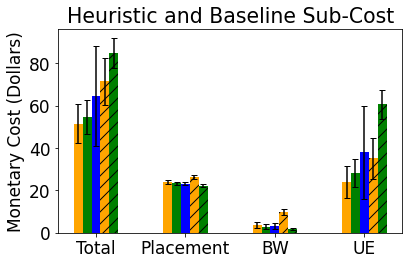

In [18]:
# Plot the plot
import matplotlib
import matplotlib.pyplot as plt

n = 3

# Set Font Size Limitations
font = {'family' : 'normal',
        'weight' : 'normal',
        'size'   : 17}

matplotlib.rc('font', **font)

# Set Labels
labels = ['Total', 'Placement', 'BW', 'UE']

# Obtain Values to Plot
SG_means = [np.mean(SG_total_sum), np.mean(SG_placement_sum), np.mean(SG_bw_sum), np.mean(SG_UE_sum)]
Batch_means = [np.mean(Batch_total_sum), np.mean(Batch_placement_sum), np.mean(Batch_bw_sum), np.mean(Batch_UE_sum)]
Myopic_means = [np.mean(Myopic_total_sum), np.mean(Myopic_placement_sum), np.mean(Myopic_bw_sum), np.mean(Myopic_UE_sum)]
Naive_means = [np.mean(Naive_total_sum), np.mean(Naive_placement_sum), np.mean(Naive_bw_sum), np.mean(Naive_UE_sum)]
Cloud_means = [np.mean(Cloud_total_sum), np.mean(Cloud_placement_sum), np.mean(Cloud_bw_sum), np.mean(Cloud_UE_sum)]


# # Double placement cost
# SG_means = [np.mean(SG_total_sum) - np.mean(SG_placement_sum)*(n-1)/n, np.mean(SG_placement_sum)/n, 
#             np.mean(SG_bw_sum), np.mean(SG_UE_sum)]
# Batch_means = [np.mean(Batch_total_sum)-np.mean(Batch_placement_sum)*(n-1)/n, np.mean(Batch_placement_sum)/n, 
#                np.mean(Batch_bw_sum), np.mean(Batch_UE_sum)]
# Myopic_means = [np.mean(Myopic_total_sum)-np.mean(Myopic_placement_sum)*(n-1)/n, np.mean(Myopic_placement_sum)/n, 
#                 np.mean(Myopic_bw_sum), np.mean(Myopic_UE_sum)]
# Naive_means = [np.mean(Naive_total_sum) - np.mean(Naive_placement_sum)*(n-1)/n, np.mean(Naive_placement_sum)/n, 
#                np.mean(Naive_bw_sum), np.mean(Naive_UE_sum)]
# Cloud_means = [np.mean(Cloud_total_sum)-np.mean(Cloud_placement_sum)*(n-1)/n, np.mean(Cloud_placement_sum)/n, 
#                np.mean(Cloud_bw_sum), np.mean(Cloud_UE_sum)]

# Half placement cost
# SG_means = [np.mean(SG_total_sum) + np.mean(SG_placement_sum)*(n-1)/n, np.mean(SG_placement_sum)*n, 
#             np.mean(SG_bw_sum), np.mean(SG_UE_sum)]
# Batch_means = [np.mean(Batch_total_sum)+np.mean(Batch_placement_sum)*(n-1)/n, np.mean(Batch_placement_sum)*n, 
#                np.mean(Batch_bw_sum), np.mean(Batch_UE_sum)]
# Myopic_means = [np.mean(Myopic_total_sum)+np.mean(Myopic_placement_sum)*(n-1)/n, np.mean(Myopic_placement_sum)*n, 
#                 np.mean(Myopic_bw_sum), np.mean(Myopic_UE_sum)]
# Naive_means = [np.mean(Naive_total_sum) + np.mean(Naive_placement_sum)*(n-1)/n, np.mean(Naive_placement_sum)*n, 
#                np.mean(Naive_bw_sum), np.mean(Naive_UE_sum)]
# Cloud_means = [np.mean(Cloud_total_sum)+np.mean(Cloud_placement_sum)*(n-1)/n, np.mean(Cloud_placement_sum)*n, 
#                np.mean(Cloud_bw_sum), np.mean(Cloud_UE_sum)]



SG_var = [np.std(SG_total_sum), np.std(SG_placement_sum), np.std(SG_bw_sum), np.std(SG_UE_sum)]
Batch_var = [np.std(Batch_total_sum), np.std(Batch_placement_sum), np.std(Batch_bw_sum), np.std(Batch_UE_sum)]
Myopic_var = [np.std(Myopic_total_sum), np.std(Myopic_placement_sum), np.std(Myopic_bw_sum), np.std(Myopic_UE_sum)]
Naive_var = [np.std(Naive_total_sum), np.std(Naive_placement_sum), np.std(Naive_bw_sum), np.std(Naive_UE_sum)]
Cloud_var = [np.std(Cloud_total_sum), np.std(Cloud_placement_sum), np.std(Cloud_bw_sum), np.std(Cloud_UE_sum)]


x = np.arange(len(labels))  # the label locations
width = 0.4  # the width of the bars

fig, ax = plt.subplots()
rects1 = ax.bar(x = x - width/2, height =  Batch_means, yerr = Batch_var,
                capsize = 3, width = width/4, label='Batch', color='orange')
rects2 = ax.bar(x = x - width/4, height = SG_means, yerr = SG_var, 
                capsize = 3, width = width/4, label='Seq-Greedy', color = 'green')
rects5 = ax.bar(x = x, height = Cloud_means, yerr = Cloud_var, 
                capsize = 3, width = width/4, label='Cloud', color = 'blue')
rects3 = ax.bar(x = x + width/4, height =  Myopic_means, yerr = Myopic_var,
                capsize = 3, width = width/4, label='Myopic', color='orange',hatch='//')
rects4 = ax.bar(x = x + width/2, height = Naive_means, yerr = Naive_var, 
                capsize = 3, width = width/4, label='Naive', color = 'green',hatch='//')


# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel('Monetary Cost (Dollars)')
ax.set_title('Heuristic and Baseline Sub-Cost')
ax.set_xticks(x)
# ax.set_xlabel('Cost Type')
ax.set_xticklabels(labels)
# ax.legend()

# Set Y axis to zero
#plt.ylim(0,130)

fig.tight_layout()

plt.show()

### Pickle Results For Reproduction

Pickle the Sum values for later.

In [5]:
# import pickle

cost_stores_dic = {}
cost_stores_dic["SG"] = SG_cost_stores
cost_stores_dic["Batch"] = Batch_cost_stores
cost_stores_dic["Naive"] = Naive_cost_stores
cost_stores_dic["Myopic"] = Myopic_cost_stores
cost_stores_dic["Cloud"] = Cloud_cost_stores

pickle.dump(cost_stores_dic, open(os.path.curdir + "/sim_store/sim19/cost_store_normal.p", "wb" ) )



In [21]:
import pickle
# open a file, where you stored the pickled data
file = open(os.path.curdir + "/sim_store/sim19/cost_store_half.p", 'rb')

# dump information to that file
data = pickle.load(file)


In [22]:
SG_cost_stores2 = data["SG"]
Batch_cost_stores2 = data["Batch"]
Naive_cost_stores2 = data["Naive"]
Myopic_cost_stores2 = data["Myopic"] 
Cloud_cost_stores2 = data["Cloud"]

In [32]:
## num_trials2 = len(Batch_cost_stores)

SG_total_sum2 = np.zeros(num_trials)
SG_placement_sum2 = np.zeros(num_trials)
SG_bw_sum2 = np.zeros(num_trials)
SG_UE_sum2 = np.zeros(num_trials)

Batch_total_sum2 = np.zeros(num_trials)
Batch_placement_sum2 = np.zeros(num_trials)
Batch_bw_sum2 = np.zeros(num_trials)
Batch_UE_sum2 = np.zeros(num_trials)

Myopic_total_sum2 = np.zeros(num_trials)
Myopic_placement_sum2 = np.zeros(num_trials)
Myopic_bw_sum2 = np.zeros(num_trials)
Myopic_UE_sum2 = np.zeros(num_trials)

Naive_total_sum2 = np.zeros(num_trials)
Naive_placement_sum2 = np.zeros(num_trials)
Naive_bw_sum2 = np.zeros(num_trials)
Naive_UE_sum2 = np.zeros(num_trials)

Cloud_total_sum2 = np.zeros(num_trials)
Cloud_placement_sum2 = np.zeros(num_trials)
Cloud_bw_sum2 = np.zeros(num_trials)
Cloud_UE_sum2 = np.zeros(num_trials)

for i in range(num_trials):

    SG_total_sum2[i] += SG_cost_stores2[i].all_cost_cumulative["total_cost"][-1]
    SG_placement_sum2[i] += SG_cost_stores2[i].all_cost_cumulative["placement_cost"][-1]
    SG_bw_sum2[i] += SG_cost_stores2[i].all_cost_cumulative["srv_bw_cost"][-1]
    SG_bw_sum2[i] += SG_cost_stores2[i].all_cost_cumulative["mig_bw_cost"][-1]
    SG_UE_sum2[i] += SG_cost_stores2[i].all_cost_cumulative["thruput_cost"][-1]
    SG_UE_sum2[i] += SG_cost_stores2[i].all_cost_cumulative["latency_cost"][-1]

    Batch_total_sum2[i] += Batch_cost_stores2[i].all_cost_cumulative["total_cost"][-1]
    Batch_placement_sum2[i] += Batch_cost_stores2[i].all_cost_cumulative["placement_cost"][-1]
    Batch_bw_sum2[i] += Batch_cost_stores2[i].all_cost_cumulative["srv_bw_cost"][-1]
    Batch_bw_sum2[i] += Batch_cost_stores2[i].all_cost_cumulative["mig_bw_cost"][-1]
    Batch_UE_sum2[i] += Batch_cost_stores2[i].all_cost_cumulative["thruput_cost"][-1]
    Batch_UE_sum2[i] += Batch_cost_stores2[i].all_cost_cumulative["latency_cost"][-1]
    
    Myopic_total_sum2[i] += Myopic_cost_stores2[i].all_cost_cumulative["total_cost"][-1]
    Myopic_placement_sum2[i] += Myopic_cost_stores2[i].all_cost_cumulative["placement_cost"][-1]
    Myopic_bw_sum2[i] += Myopic_cost_stores2[i].all_cost_cumulative["srv_bw_cost"][-1]
    Myopic_bw_sum2[i] += Myopic_cost_stores2[i].all_cost_cumulative["mig_bw_cost"][-1]
    Myopic_UE_sum2[i] += Myopic_cost_stores2[i].all_cost_cumulative["thruput_cost"][-1]
    Myopic_UE_sum2[i] += Myopic_cost_stores2[i].all_cost_cumulative["latency_cost"][-1]
    
    Naive_total_sum2[i] += Naive_cost_stores2[i].all_cost_cumulative["total_cost"][-1]
    Naive_placement_sum2[i] += Naive_cost_stores2[i].all_cost_cumulative["placement_cost"][-1]
    Naive_bw_sum2[i] += Naive_cost_stores2[i].all_cost_cumulative["srv_bw_cost"][-1]
    Naive_bw_sum2[i] += Naive_cost_stores2[i].all_cost_cumulative["mig_bw_cost"][-1]
    Naive_UE_sum2[i] += Naive_cost_stores2[i].all_cost_cumulative["thruput_cost"][-1]
    Naive_UE_sum2[i] += Naive_cost_stores2[i].all_cost_cumulative["latency_cost"][-1]
    
    Cloud_total_sum2[i] += Cloud_cost_stores2[i].all_cost_cumulative["total_cost"][-1]
    Cloud_placement_sum2[i] += Cloud_cost_stores2[i].all_cost_cumulative["placement_cost"][-1]
    Cloud_bw_sum2[i] += Cloud_cost_stores2[i].all_cost_cumulative["srv_bw_cost"][-1]
    Cloud_bw_sum2[i] += Cloud_cost_stores2[i].all_cost_cumulative["mig_bw_cost"][-1]
    Cloud_UE_sum2[i] += Cloud_cost_stores2[i].all_cost_cumulative["thruput_cost"][-1]
    Cloud_UE_sum2[i] += Cloud_cost_stores2[i].all_cost_cumulative["latency_cost"][-1]

In [35]:
# Half
SG_means2 = [np.mean(SG_total_sum2) + np.mean(SG_placement_sum2)*(n-1)/n, np.mean(SG_placement_sum2)*n, 
            np.mean(SG_bw_sum2), np.mean(SG_UE_sum2)]
Batch_means2 = [np.mean(Batch_total_sum2)+np.mean(Batch_placement_sum2)*(n-1)/n, np.mean(Batch_placement_sum2)*n, 
               np.mean(Batch_bw_sum2), np.mean(Batch_UE_sum2)]
Myopic_means2 = [np.mean(Myopic_total_sum2)+np.mean(Myopic_placement_sum2)*(n-1)/n, np.mean(Myopic_placement_sum2)*n, 
                np.mean(Myopic_bw_sum2), np.mean(Myopic_UE_sum2)]
Naive_means2 = [np.mean(Naive_total_sum2) + np.mean(Naive_placement_sum2)*(n-1)/n, np.mean(Naive_placement_sum2)*n, 
               np.mean(Naive_bw_sum2), np.mean(Naive_UE_sum2)]
Cloud_means2 = [np.mean(Cloud_total_sum2)+np.mean(Cloud_placement_sum2)*(n-1)/n, np.mean(Cloud_placement_sum2)*n, 
               np.mean(Cloud_bw_sum2), np.mean(Cloud_UE_sum2)]

In [37]:
np.set_printoptions(precision=3)
print("N/3 Placement Weight") # Decreased importance on placement during derivation
print('Batch ', Batch_means2)
print('SG    ', SG_means2)
print('Cloud ', Cloud_means2)
print('Myopic', Myopic_means2)
print('Naive ', Naive_means2)

N/3 Resource Weight
Batch  [44.12117637691028, 25.696830919120107, 4.402215885315227, 25.442943314306103]
SG     [49.50597953254918, 24.607577988918905, 3.5506588852492778, 32.284443986789405]
Cloud  [64.2244921952886, 24.35834240253154, 3.907084993915769, 46.78499475552197]
Myopic [63.78092306574713, 28.10252960238338, 10.196814400407607, 37.97159221957099]
Naive  [78.4405461912132, 23.024043402247905, 1.9284015783917927, 63.72100938935033]


In [36]:
np.set_printoptions(precision=3)
print("Triple Placement Weight") # Increased importance on placement during derivation
print('Batch ', Batch_means)
print('SG    ', SG_means)
print('Cloud ', Cloud_means)
print('Myopic', Myopic_means)
print('Naive ', Naive_means)

Triple Resource Weight
Batch  [55.182752179444925, 23.0318780642929, 3.009406780025887, 29.14146733512613]
SG     [60.54311790891782, 22.07381134120763, 2.2743092050920275, 36.194997362618146]
Cloud  [86.41859338820476, 21.819423285635185, 2.890321461431305, 61.70884864113823]
Myopic [73.37158622164671, 26.555640343004097, 9.910078498480477, 36.90586738016209]
Naive  [90.20535865348265, 21.859448723945935, 1.7773443473813575, 66.56856558215534]


In [12]:
np.set_printoptions(precision=3)
print("Normal Placement Weight") # Increased importance on placement during derivation
print('Batch ', Batch_means)
print('SG    ', SG_means)
print('Cloud ', Cloud_means)
print('Myopic', Myopic_means)
print('Naive ', Naive_means)

Normal Placement Weight
Batch  [51.55861345816811, 24.042528998956797, 3.487068176362091, 24.029016282849227]
SG     [54.650307536035506, 23.364965042532674, 2.9040164526366903, 28.381326040866146]
Cloud  [64.42465467822731, 23.260408334550608, 3.186073116916435, 37.97817322676027]
Myopic [71.50229352402548, 26.476072913771667, 9.879578633291267, 35.14664197696253]
Naive  [84.82381362801928, 22.315827082253286, 1.773067009056015, 60.734919536709995]


In [13]:
# N/3 Resource Weight
Batch_n_3 =  [51.55861345816811, 24.042528998956797, 3.487068176362091, 24.029016282849227]
SG_n_3 =     [54.650307536035506, 23.364965042532674, 2.9040164526366903, 28.381326040866146]
Cloud_n_3 =  [64.42465467822731, 23.260408334550608, 3.186073116916435, 37.97817322676027]
Myopic_n_3 = [71.50229352402548, 26.476072913771667, 9.879578633291267, 35.14664197696253]
Naive_n_3 =  [84.82381362801928, 22.315827082253286, 1.773067009056015, 60.734919536709995]

# Normal Placement Weight
Batch_n =   [44.12117637691028, 25.696830919120107, 4.402215885315227, 25.442943314306103]
SG_n =      [49.50597953254918, 24.607577988918905, 3.5506588852492778, 32.284443986789405]
Cloud_n =   [64.2244921952886, 24.35834240253154, 3.907084993915769, 46.78499475552197]
Myopic_n =  [63.78092306574713, 28.10252960238338, 10.196814400407607, 37.97159221957099]
Naive_n =   [78.4405461912132, 23.024043402247905, 1.9284015783917927, 63.72100938935033]

# Triple Resource Weight
Batch_3n =   [55.182752179444925, 23.0318780642929, 3.009406780025887, 29.14146733512613]
SG_3n =      [60.54311790891782, 22.07381134120763, 2.2743092050920275, 36.194997362618146]
Cloud_3n =   [86.41859338820476, 21.819423285635185, 2.890321461431305, 61.70884864113823]
Myopic_3n =  [73.37158622164671, 26.555640343004097, 9.910078498480477, 36.90586738016209]
Naive_3n =   [90.20535865348265, 21.859448723945935, 1.7773443473813575, 66.56856558215534]

### Plot individual values and compare
1. Placement cost
2. Latency Cost
3. Total Cost

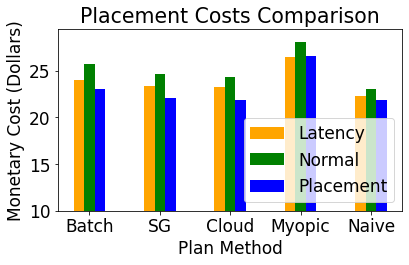

In [65]:
# Placement Cost Plot
val = 1
p_n_3 = [Batch_n_3[val], SG_n_3[val], Cloud_n_3[val], Myopic_n_3[val], Naive_n_3[val]]
p_n = [Batch_n[val], SG_n[val], Cloud_n[val], Myopic_n[val], Naive_n[val]]
p_n3 = [Batch_3n[val], SG_3n[val], Cloud_3n[val], Myopic_3n[val], Naive_3n[val]]

# Set Font Size Limitations
font = {'family' : 'normal',
        'weight' : 'normal',
        'size'   : 17}

matplotlib.rc('font', **font)

# Set Labels
labels = ['Batch', 'SG', 'Cloud', 'Myopic', 'Naive']


x = np.arange(len(labels))  # the label locations
width = 0.6  # the width of the bars

fig, ax = plt.subplots()
rects1 = ax.bar(x = x - width/4, height =  p_n_3,
                capsize = 3, width = width/4, label="Latency", color='orange')
rects2 = ax.bar(x = x, height = p_n, 
                capsize = 3, width = width/4, label="Normal", color = 'green')
rects5 = ax.bar(x = x+width/4, height = p_n3, 
                capsize = 3, width = width/4, label="Placement", color = 'blue')

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel('Monetary Cost (Dollars)')
ax.set_title('Placement Costs Comparison')
ax.set_xticks(x)
ax.set_xlabel('Plan Method')
ax.set_xticklabels(labels)
ax.legend(loc='lower right')

# Set Y axis to zero
plt.ylim(10,)

fig.tight_layout()

plt.show()

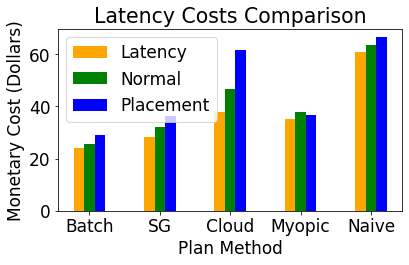

In [68]:
# Latency Cost Plot
val = 3
p_n_3 = [Batch_n_3[val], SG_n_3[val], Cloud_n_3[val], Myopic_n_3[val], Naive_n_3[val]]
p_n = [Batch_n[val], SG_n[val], Cloud_n[val], Myopic_n[val], Naive_n[val]]
p_n3 = [Batch_3n[val], SG_3n[val], Cloud_3n[val], Myopic_3n[val], Naive_3n[val]]

# Set Font Size Limitations
font = {'family' : 'normal',
        'weight' : 'normal',
        'size'   : 17}

matplotlib.rc('font', **font)

# Set Labels
labels = ['Batch', 'SG', 'Cloud', 'Myopic', 'Naive']


x = np.arange(len(labels))  # the label locations
width = 0.6  # the width of the bars

fig, ax = plt.subplots()
rects1 = ax.bar(x = x - width/4, height =  p_n_3,
                capsize = 3, width = width/4, label="Latency", color='orange')
rects2 = ax.bar(x = x, height = p_n, 
                capsize = 3, width = width/4, label="Normal", color = 'green')
rects5 = ax.bar(x = x+width/4, height = p_n3, 
                capsize = 3, width = width/4, label="Placement", color = 'blue')

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel('Monetary Cost (Dollars)')
ax.set_title('Latency Costs Comparison')
ax.set_xticks(x)
ax.set_xlabel('Plan Method')
ax.set_xticklabels(labels)
ax.legend()

# Set Y axis to zero
plt.ylim(0,)

fig.tight_layout()

plt.show()

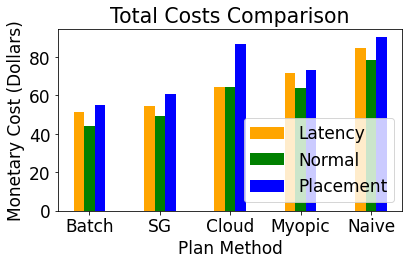

In [71]:
# Latency Cost Plot
val = 0
p_n_3 = [Batch_n_3[val], SG_n_3[val], Cloud_n_3[val], Myopic_n_3[val], Naive_n_3[val]]
p_n = [Batch_n[val], SG_n[val], Cloud_n[val], Myopic_n[val], Naive_n[val]]
p_n3 = [Batch_3n[val], SG_3n[val], Cloud_3n[val], Myopic_3n[val], Naive_3n[val]]

# Set Font Size Limitations
font = {'family' : 'normal',
        'weight' : 'normal',
        'size'   : 17}

matplotlib.rc('font', **font)

# Set Labels
labels = ['Batch', 'SG', 'Cloud', 'Myopic', 'Naive']


x = np.arange(len(labels))  # the label locations
width = 0.6  # the width of the bars

fig, ax = plt.subplots()
rects1 = ax.bar(x = x - width/4, height =  p_n_3,
                capsize = 3, width = width/4, label="Latency", color='orange')
rects2 = ax.bar(x = x, height = p_n, 
                capsize = 3, width = width/4, label="Normal", color = 'green')
rects5 = ax.bar(x = x+width/4, height = p_n3, 
                capsize = 3, width = width/4, label="Placement", color = 'blue')

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel('Monetary Cost (Dollars)')
ax.set_title('Total Costs Comparison')
ax.set_xticks(x)
ax.set_xlabel('Plan Method')
ax.set_xticklabels(labels)
ax.legend(loc = 'lower right')

# Set Y axis to zero
plt.ylim(0,)

fig.tight_layout()

plt.show()